# PHÂN TÍCH ĐA BIẾN: GHÉP BIẾN THÀNH MÔ HÌNH


In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("/home/kieu/Documents/scorecard/DATA")
OUTPUT_DIR = Path("/home/kieu/Documents/scorecard/output")
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET = "TARGET" 

## Phần A — Shortlist & WoE Transformation

In [11]:
# Shortlist sau phân tích đơn biến 
# Mỗi biến khai báo Ở ĐÚNG MỘT trong hai danh sách dưới đây, tùy nguồn luật bạn muốn dùng.

VARS_TREND_RAW = [  
'OWN_CAR_AGE',
'AGE_YEARS',
'EXT_SOURCE_1',
'EXT_SOURCE_2',
'EXT_SOURCE_3',
'EXT_SOURCE_AVG',
'bureau_active_cnt',
'bureau_closed_cnt',
'bureau_debt_ratio',
'bureau_open_9m',
'approved_cnt',
'refused_cnt',
'prev_app_credit_ratio',
'prev_revolving_loan_cnt',
'first_decision_days',
'refused_12m',
'avg_days_late',
'late_payment_cnt',
'late_6m',
'total_inst_prescribed',
'total_inst_paid',
'total_pay_ratio',
'avg_payment_diff',
'pos_max_dpd_def',
'pos_completed_cnt',
'cc_avg_balance',
'cc_max_balance',
'cc_avg_utilization',
'cc_util_12m',
'cc_total_drawings_cnt',
'bureau_active_ratio',
'bureau_debt_income_ratio',
'approval_rate',
'refusal_rate',
'late_payment_ratio',
'late_ratio_12m',
'underpay_ratio',
'pos_dpd_ratio',
'AMT_ANNUITY' 
]

VARS_TREND_EP = [  
'AMT_CREDIT',
'LTV_RATIO',
'total_bureau_debt',
'inst_cnt_3m',
'underpay_cnt',
'pos_active_cnt'  
]

SELECTED_VARS = VARS_TREND_RAW + VARS_TREND_EP

# --- QC bắt buộc: một biến không được vừa "gốc" vừa "ép" — sẽ không biết dùng luật nào ---
trung = set(VARS_TREND_RAW) & set(VARS_TREND_EP)
assert not trung, f"Các biến sau xuất hiện ở CẢ HAI danh sách, chỉ được chọn 1 nguồn luật: {trung}"

# --- QC: không liệt kê trùng trong nội bộ từng danh sách ---
assert len(SELECTED_VARS) == len(set(SELECTED_VARS)), "Có biến bị liệt kê trùng lặp trong cùng 1 danh sách."

print(f"Shortlist: {len(SELECTED_VARS)} biến "
      f"({len(VARS_TREND_RAW)} theo trend GỐC + {len(VARS_TREND_EP)} theo trend ĐÃ ÉP)")


Shortlist: 45 biến (39 theo trend GỐC + 6 theo trend ĐÃ ÉP)


### A2. WoE transformation: đổi "đơn vị đo" cho mọi biến

Thay **giá trị gốc** của khách hàng bằng **WoE của bin chứa nó** :

**Hệ quả quan trọng:** sau bước này mọi biến cùng thang đo log-odds → hệ số hồi quy kỳ vọng **cùng dấu**. Nếu sau này thấy hệ số lộn dấu — đó là chuông báo đa cộng tuyến, dẫn thẳng vào Phần B.\n\n**Về nguồn luật hỗn hợp:** hàm `apply_woe_transformation` bên dưới không cần biết một dòng luật đến từ sheet `bin_theo_trend_raw` hay `bin_theo_trend_ep` — nó chỉ tra theo `variable`/`cut_point`/`min`/`max`/`woe`. Việc \"biến nào lấy luật ở sheet nào\" đã được quyết định dứt điểm ở ô `VARS_TREND_RAW`/`VARS_TREND_EP` phía trên, trước khi vào hàm này.

In [12]:
def apply_woe_transformation(df_raw, df_rules, features):
    """Chuyển dữ liệu gốc sang dữ liệu WoE theo bảng luật binning (dùng cho tập Train)."""
    print("1. Đang chuyển đổi dữ liệu gốc sang dữ liệu WoE...")
    df_woe = pd.DataFrame()
    df_woe[TARGET] = df_raw[TARGET]

    for col in features:
        var_rules = df_rules[df_rules['variable'] == col]
        if var_rules.empty:
            continue

        df_woe[col] = np.nan   # khởi tạo, sẽ điền dần theo luật

        # (1) Nhóm Missing: khách NaN nhận WoE riêng của dòng 'Missing'
        m_rule = var_rules[var_rules['cut_point'] == 'Missing']
        if not m_rule.empty:
            df_woe.loc[df_raw[col].isna(), col] = m_rule['woe'].values[0]

        # (2) Các bin thường (loại dòng Missing & Outlier ra khỏi luật đang xét)
        normal_rules = var_rules[~var_rules['cut_point'].isin(['Missing'])
                                 & ~var_rules['cut_point'].astype(str).str.contains('Outlier')]
        is_categorical = df_raw[col].dtype == 'object'

        if is_categorical:
            # Nhánh chữ: tra đúng giá trị; giá trị lạ rơi vào nhóm OTHERS
            for _, r in normal_rules.iterrows():
                val, woe_val = r['cut_point'], r['woe']
                if val == 'OTHERS':
                    known_cats = normal_rules['cut_point'].tolist()
                    df_woe.loc[~df_raw[col].isna() & ~df_raw[col].isin(known_cats), col] = woe_val
                else:
                    df_woe.loc[df_raw[col] == val, col] = woe_val
        else:
            # Nhánh số: tra theo khoảng [min, max)
            for _, r in normal_rules.iterrows():
                cond = (df_raw[col] >= float(r['min'])) & (df_raw[col] < float(r['max']))
                df_woe.loc[cond, col] = r['woe']

    return df_woe


# --- Thực thi ---
df_raw = pd.read_csv(OUTPUT_DIR / "0.data_train_split.csv")   # CHỈ Train — Validation giữ nguyên, không đụng tới

# Đọc CẢ HAI sheet — đây là 2 bảng bin có cut_point khác nhau thật sự (xem A1), không gộp chung.
BINNING_REPORT_PATH = OUTPUT_DIR / "1.binning_survey_report.xlsx"
rules_raw = pd.read_excel(BINNING_REPORT_PATH, sheet_name="bin_theo_trend_raw")
rules_ep = pd.read_excel(BINNING_REPORT_PATH, sheet_name="bin_theo_trend_ep")

# QC: mọi biến trong 2 danh sách ở ô trên phải THẬT SỰ có mặt trong đúng sheet tương ứng
# (bắt lỗi gõ nhầm tên biến hoặc biến không tồn tại trong báo cáo Buổi 2 — thay vì để
# apply_woe_transformation âm thầm bỏ qua và mọi giá trị của biến đó biến thành 0 ở VIF).
thieu_raw = set(VARS_TREND_RAW) - set(rules_raw['variable'])
thieu_ep = set(VARS_TREND_EP) - set(rules_ep['variable'])
assert not thieu_raw, f"Các biến sau KHÔNG có trong sheet 'bin_theo_trend_raw': {thieu_raw}"
assert not thieu_ep, f"Các biến sau KHÔNG có trong sheet 'bin_theo_trend_ep': {thieu_ep}"

# Ghép lại thành MỘT bảng luật duy nhất — mỗi biến chỉ mang đúng 1 bộ luật, theo đúng
# lựa chọn đã khai báo ở ô VARS_TREND_RAW/VARS_TREND_EP phía trên.
df_rules = pd.concat([
    rules_raw[rules_raw['variable'].isin(VARS_TREND_RAW)],
    rules_ep[rules_ep['variable'].isin(VARS_TREND_EP)],
], ignore_index=True)

df_woe = apply_woe_transformation(df_raw, df_rules, SELECTED_VARS)
df_woe = df_woe.fillna(0)   # ô sót (nếu có) điền 0 để bước VIF không lỗi

# So sánh trước/sau trên 1 biến của MỖI nguồn luật cho "thấm"
_demo_raw = VARS_TREND_RAW[0] if VARS_TREND_RAW else None
_demo_ep = VARS_TREND_EP[0] if VARS_TREND_EP else None
print(f"Ví dụ biến lấy luật từ sheet GỐC : {_demo_raw}")
print(f"Ví dụ biến lấy luật từ sheet ĐÃ ÉP: {_demo_ep}")
pd.DataFrame({
    f'gốc ({_demo_ep})': df_raw[_demo_ep].head(8).round(4),
    'sau WoE': df_woe[_demo_ep].head(8).round(4),
})

1. Đang chuyển đổi dữ liệu gốc sang dữ liệu WoE...
Ví dụ biến lấy luật từ sheet GỐC : OWN_CAR_AGE
Ví dụ biến lấy luật từ sheet ĐÃ ÉP: AMT_CREDIT


,gốc (AMT_CREDIT),sau WoE
0,679500.0,0.1129
1,900000.0,0.1129
2,526491.0,-0.1235
3,573628.5,-0.1235
4,760131.0,0.1129
5,604152.0,-0.1235
6,1762110.0,0.4715
7,247675.5,-0.1235


## Phần B1 — Ma trận tương quan (soi nhanh trước khi vào VIF)

**Ngưỡng tham khảo:** |tương quan| > 0.7 là cặp biến đáng chú ý (không tự động loại — tương quan cặp không bắt được đa cộng tuyến *đa biến*, đó là lý do vẫn cần VIF chính thức ở Phần B2. Ví dụ kinh điển: 3 biến đôi một tương quan vừa phải nhưng cộng lại gây đa cộng tuyến nặng — correlation cặp không thấy được, VIF thấy được).

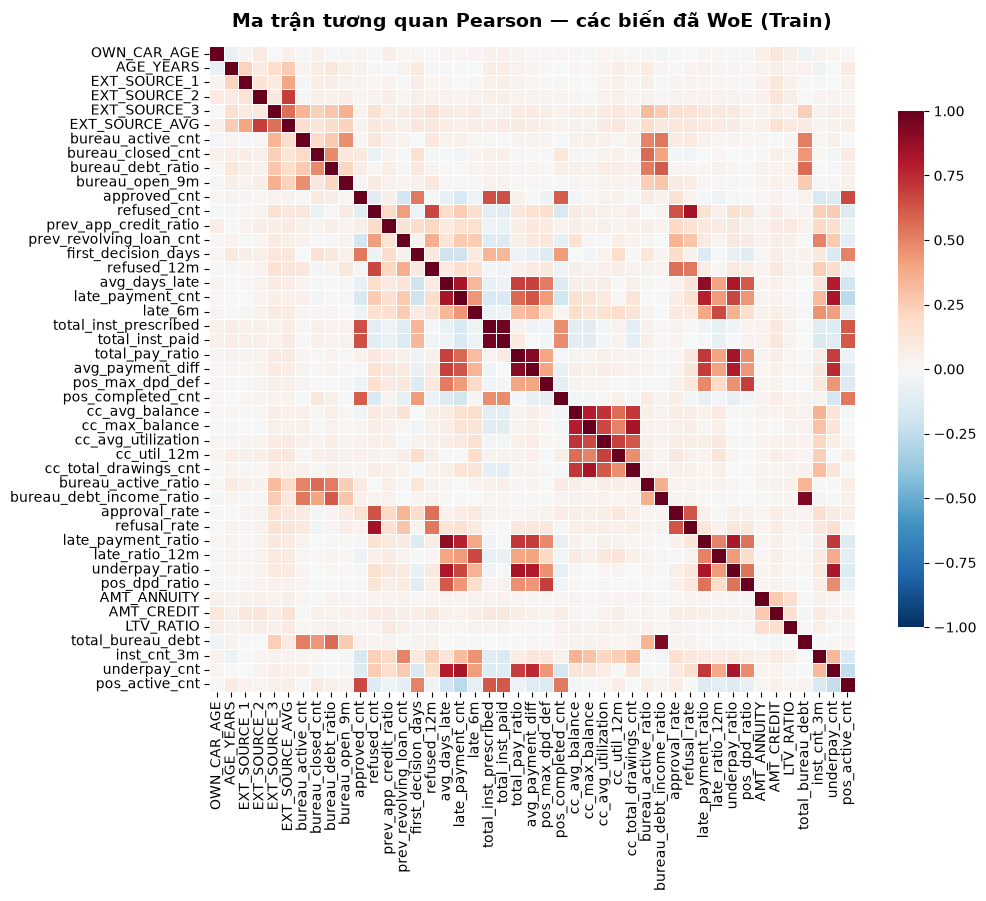

✅ Đã lưu: 2b.correlation_heatmap.png

Cặp biến |tương quan| > 0.7:
                  bien_1                bien_2     corr
   total_inst_prescribed       total_inst_paid 0.961993
bureau_debt_income_ratio     total_bureau_debt 0.928893
         total_pay_ratio      avg_payment_diff 0.913641
           avg_days_late    late_payment_ratio 0.885070
             refused_cnt          refusal_rate 0.843458
        late_payment_cnt          underpay_cnt 0.825253
           avg_days_late      late_payment_cnt 0.824903
         total_pay_ratio        underpay_ratio 0.821850
          cc_max_balance cc_total_drawings_cnt 0.821000
          underpay_ratio          underpay_cnt 0.818339
      late_payment_ratio        underpay_ratio 0.817926
           avg_days_late        underpay_ratio 0.805050
        avg_payment_diff        underpay_ratio 0.798965
          cc_avg_balance        cc_max_balance 0.788933
           avg_days_late          underpay_cnt 0.786630
        late_payment_cnt    late_paym

In [13]:
CORR_THRESHOLD = 0.7   # ngưỡng tham khảo để liệt kê cặp biến đáng chú ý (không tự động loại)

corr_matrix = df_woe.drop(columns=[TARGET]).corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_matrix, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Ma trận tương quan Pearson — các biến đã WoE (Train)", fontsize=14, fontweight="bold", pad=14)
plt.tight_layout()
CORR_CHART_PATH = OUTPUT_DIR / "2b.correlation_heatmap.png"
plt.savefig(CORR_CHART_PATH, dpi=200, bbox_inches="tight")
plt.show()
print(f"✅ Đã lưu: {CORR_CHART_PATH.name}")

# Liệt kê các cặp vượt ngưỡng — nguyên liệu cho trò chơi đoán biến bị VIF loại
pairs = (corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
         .stack().rename("corr").reset_index())
pairs.columns = ["bien_1", "bien_2", "corr"]
pairs_manh = pairs[pairs["corr"].abs() > CORR_THRESHOLD].sort_values("corr", key=abs, ascending=False)

print(f"\nCặp biến |tương quan| > {CORR_THRESHOLD}:")
if len(pairs_manh):
    print(pairs_manh.to_string(index=False))
else:
    print("(không có cặp nào vượt ngưỡng)")

## Phần B2 — Đa cộng tuyến & VIF (kiểm định chính thức)

$$VIF(X_i) = \frac{1}{1 - R_i^2}$$

trong đó $R_i^2$ là R² khi hồi quy $X_i$ theo **tất cả biến còn lại**. $X_i$ càng "đoán được" từ các biến khác → VIF càng cao.

**Tham số của phần này:** ngưỡng loại biến. Quy ước phổ biến của ngành ngân hàng: **VIF > 5 là đa cộng tuyến đáng kể** (một số nơi dùng 10 — dễ dãi hơn; scorecard cần hệ số ổn định để scale điểm nên chọn 5).

Thuật toán: vòng lặp **loại biến VIF cao nhất → tính lại toàn bộ → lặp** đến khi sạch. Vì sao loại từng biến một? Vì loại một biến làm VIF của tất cả biến còn lại thay đổi — loại một lượt sẽ "giết oan".


In [14]:
VIF_THRESHOLD = 5.0   # VIF > 5 -> đa cộng tuyến -> loại


def vif_filter(df_features, threshold=VIF_THRESHOLD):
    print(f"\n2. Bắt đầu lọc đa cộng tuyến (ngưỡng VIF = {threshold})...")
    X = df_features.copy()

    # Loại cột phương sai = 0 (hằng số) để tránh chia 0
    X = X.loc[:, X.var() > 0]

    dropped = True
    while dropped:
        # Bắt buộc thêm hằng số (constant) để VIF tính chính xác
        X_with_const = add_constant(X)

        vif_data = pd.DataFrame()
        vif_data["feature"] = X_with_const.columns
        vif_data["VIF"] = [variance_inflation_factor(X_with_const.values, i)
                           for i in range(X_with_const.shape[1])]
        vif_data = vif_data[vif_data['feature'] != 'const']

        max_vif = vif_data['VIF'].max()
        if max_vif > threshold:
            # Loại đúng MỘT biến tệ nhất rồi tính lại từ đầu
            max_feature = vif_data.loc[vif_data['VIF'] == max_vif, 'feature'].values[0]
            print(f" - Loại bỏ: {max_feature} \t(VIF = {max_vif:.2f})")
            X = X.drop(columns=[max_feature])
            dropped = True
        else:
            dropped = False

    print(f"\n✅ Hoàn thành! Giữ lại được {X.shape[1]} biến không bị đa cộng tuyến.")
    return X.columns.tolist()


X_features = df_woe.drop(columns=[TARGET])
final_vif_vars = vif_filter(X_features)


2. Bắt đầu lọc đa cộng tuyến (ngưỡng VIF = 5.0)...
 - Loại bỏ: total_inst_paid 	(VIF = 14.65)
 - Loại bỏ: bureau_debt_income_ratio 	(VIF = 8.58)
 - Loại bỏ: total_pay_ratio 	(VIF = 7.90)
 - Loại bỏ: avg_days_late 	(VIF = 7.88)
 - Loại bỏ: underpay_cnt 	(VIF = 7.09)
 - Loại bỏ: refused_cnt 	(VIF = 5.63)
 - Loại bỏ: late_payment_ratio 	(VIF = 5.06)

✅ Hoàn thành! Giữ lại được 38 biến không bị đa cộng tuyến.


In [15]:
# Lưu bộ dữ liệu sạch (đã WoE + lọc VIF) cho bước Stepwise
WOE_VIF_DATA_PATH = OUTPUT_DIR / "2.data_woe_vif_filtered.csv"
df_woe[[TARGET] + final_vif_vars].to_csv(WOE_VIF_DATA_PATH, index=False)
print(f"\n💾 Đã lưu: {WOE_VIF_DATA_PATH}")


💾 Đã lưu: /home/kieu/Documents/scorecard/output/2.data_woe_vif_filtered.csv


## Phần C — Forward Selection tối ưu Gini

Thuật toán tham lam theo chiều tiến:
1. Bắt đầu với 0 biến;
2. Mỗi bước: **thử từng biến còn lại**, giữ biến làm Gini tăng nhiều nhất;
3. Dừng khi đủ số biến mục tiêu.

**Tham số của phần này:** dừng ở bao nhiêu biến? Ngành retail banking chuộng scorecard **6–10 biến**: mỗi biến thêm vào là thêm một trường dữ liệu phải thu thập, kiểm tra chất lượng, giải trình với thẩm định và monitor sau triển khai.

In [16]:
MAX_FEATURES = 8   # số biến tối đa của scorecard (chuẩn ngành: 6-10)


def find_best_combination_and_report(X, y, max_features=MAX_FEATURES):
    """Forward Selection tối ưu hóa Gini và in báo cáo chi tiết."""
    features_pool = list(X.columns)
    selected_features = []

    # Model "nháp" để chấm Gini nhanh cho từng tổ hợp thử
    fast_model = LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000)

    print("=" * 80)
    print(f"TIẾN TRÌNH TÌM KIẾM TỔ HỢP {max_features} BIẾN TỐI ƯU")
    print("=" * 80)

    prev_gini = 0
    for k in range(1, max_features + 1):
        best_gini = 0
        best_feature_to_add = None

        # Thử lần lượt TỪNG biến còn lại trong pool
        for feature in features_pool:
            test_features = selected_features + [feature]
            fast_model.fit(X[test_features], y)
            y_prob = fast_model.predict_proba(X[test_features])[:, 1]
            gini = (2 * roc_auc_score(y, y_prob) - 1) * 100

            if gini > best_gini:
                best_gini = gini
                best_feature_to_add = feature

        # Chốt biến thắng cuộc của vòng này
        if best_feature_to_add:
            selected_features.append(best_feature_to_add)
            features_pool.remove(best_feature_to_add)
            diff = best_gini - prev_gini
            print(f"Bước {k}: Thêm '{best_feature_to_add}' -> Gini: {best_gini:.2f}% (Tăng: +{diff:.2f}%)")
            prev_gini = best_gini

    print("\n" + "-" * 30)
    print(f"🚫 CÁC BIẾN BỊ LOẠI (không nằm trong Top {max_features} đóng góp Gini):")
    for rejected in features_pool:
        print(f" - {rejected}")
    print("-" * 30)

    # Hồi quy Logistic CHÍNH THỨC bằng statsmodels -> báo cáo đầy đủ
    print("\n" + "=" * 80)
    print("BÁO CÁO CHI TIẾT MÔ HÌNH HỒI QUY (LOGISTIC REGRESSION SUMMARY)")
    print("=" * 80)
    X_final = sm.add_constant(X[selected_features])
    final_model = sm.Logit(y, X_final).fit(disp=0)
    print(final_model.summary2())

    return selected_features, final_model


# --- Thực thi ---
df_clean = pd.read_csv(WOE_VIF_DATA_PATH)
y = df_clean[TARGET]
X = df_clean.drop(columns=[TARGET, 'SK_ID_CURR'], errors='ignore').fillna(0)

best_vars, model_object = find_best_combination_and_report(X, y)

# Xuất file cho Buổi 4
STEPWISE_FEATURES_PATH = OUTPUT_DIR / "3.final_stepwise_features.csv"
FINAL_MODEL_DATA_PATH = OUTPUT_DIR / "3.data_final_model.csv"
pd.DataFrame({'Selected_Features': best_vars}).to_csv(STEPWISE_FEATURES_PATH, index=False)
df_clean[[TARGET] + best_vars].to_csv(FINAL_MODEL_DATA_PATH, index=False)
print(f"\n✅ Đã xuất: {STEPWISE_FEATURES_PATH.name} và {FINAL_MODEL_DATA_PATH.name}")

TIẾN TRÌNH TÌM KIẾM TỔ HỢP 8 BIẾN TỐI ƯU
Bước 1: Thêm 'EXT_SOURCE_AVG' -> Gini: 40.47% (Tăng: +40.47%)
Bước 2: Thêm 'LTV_RATIO' -> Gini: 42.78% (Tăng: +2.31%)
Bước 3: Thêm 'late_ratio_12m' -> Gini: 44.31% (Tăng: +1.53%)
Bước 4: Thêm 'cc_util_12m' -> Gini: 45.28% (Tăng: +0.97%)
Bước 5: Thêm 'prev_app_credit_ratio' -> Gini: 46.12% (Tăng: +0.83%)
Bước 6: Thêm 'bureau_debt_ratio' -> Gini: 46.82% (Tăng: +0.71%)
Bước 7: Thêm 'refusal_rate' -> Gini: 47.36% (Tăng: +0.54%)
Bước 8: Thêm 'total_inst_prescribed' -> Gini: 47.82% (Tăng: +0.46%)

------------------------------
🚫 CÁC BIẾN BỊ LOẠI (không nằm trong Top 8 đóng góp Gini):
 - OWN_CAR_AGE
 - AGE_YEARS
 - EXT_SOURCE_1
 - EXT_SOURCE_2
 - EXT_SOURCE_3
 - bureau_active_cnt
 - bureau_closed_cnt
 - bureau_open_9m
 - approved_cnt
 - prev_revolving_loan_cnt
 - first_decision_days
 - refused_12m
 - late_payment_cnt
 - late_6m
 - avg_payment_diff
 - pos_max_dpd_def
 - pos_completed_cnt
 - cc_avg_balance
 - cc_max_balance
 - cc_avg_utilization
 - cc_t

## Phần D — Gini & KS: hai thước đo sức phân biệt

$$GINI = 2 \times AUC - 1 \qquad\qquad KS = \max_x \big( CumBad(x) - CumGood(x) \big)$$

- **Gini**: xếp ngẫu nhiên = 0%. Chuẩn ngành retail: **40–60% là mô hình tốt**;
- **KS**: sắp khách theo rủi ro giảm dần, KS là khoảng hở dọc lớn nhất giữa 2 đường tích lũy bad/good — KS cao nghĩa là tồn tại một điểm cắt tách bad/good rất rõ, nền tảng chọn **cut-off phê duyệt**.

In [17]:
# Huấn luyện lại mô hình chốt để lấy xác suất (deterministic — kết quả y hệt Phần C)
df_model = pd.read_csv(FINAL_MODEL_DATA_PATH)
y = df_model[TARGET]
X = df_model.drop(columns=[TARGET, 'SK_ID_CURR'], errors='ignore')

lr_model = LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000)
lr_model.fit(X, y)
y_prob = lr_model.predict_proba(X)[:, 1]

# --- Gini & đường ROC ---
auc = roc_auc_score(y, y_prob)
gini = (2 * auc - 1) * 100
fpr, tpr, thresholds = roc_curve(y, y_prob)

# --- KS: sắp khách từ rủi ro CAO NHẤT -> thấp nhất, tích lũy 2 đường ---
df_ks = pd.DataFrame({'target': y, 'prob': y_prob})
df_ks = df_ks.sort_values(by='prob', ascending=False).reset_index(drop=True)
df_ks['bads'] = df_ks['target']
df_ks['goods'] = 1 - df_ks['target']
df_ks['cum_bads'] = df_ks['bads'].cumsum() / df_ks['bads'].sum()
df_ks['cum_goods'] = df_ks['goods'].cumsum() / df_ks['goods'].sum()
df_ks['ks_diff'] = df_ks['cum_bads'] - df_ks['cum_goods']
ks_stat = df_ks['ks_diff'].max() * 100
ks_idx = df_ks['ks_diff'].idxmax()
percentiles = np.linspace(0, 100, len(df_ks))

print(f"AUC = {auc:.4f} | GINI = {gini:.2f}% | KS = {ks_stat:.2f}%")

AUC = 0.7391 | GINI = 47.82% | KS = 36.14%


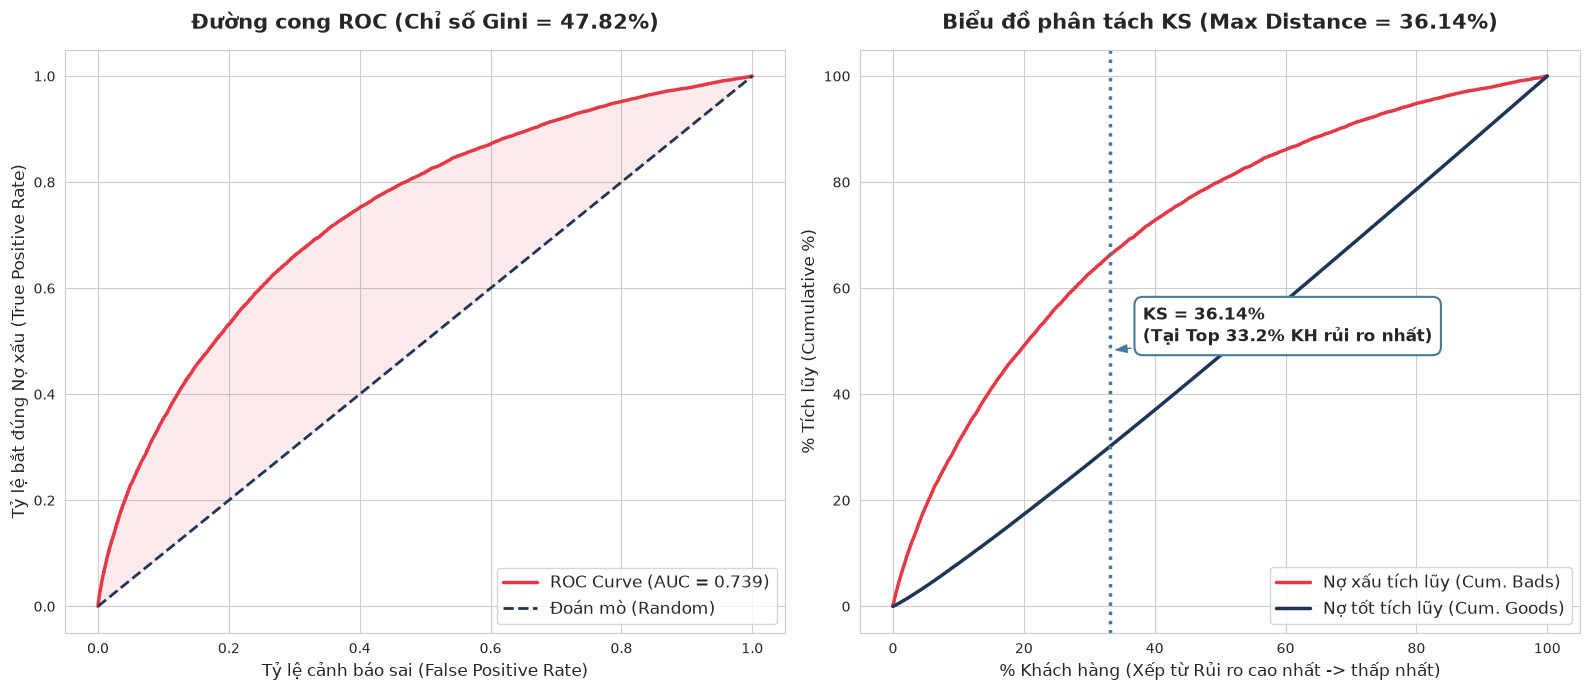

✅ Đã lưu biểu đồ: /home/kieu/Documents/scorecard/output/5.Model_Evaluation_Charts.png


In [18]:
EVAL_CHART_PATH = OUTPUT_DIR / "5.Model_Evaluation_Charts.png"

sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Biểu đồ 1: ROC & Gini ---
ax1 = axes[0]
ax1.plot(fpr, tpr, color='#E63946', lw=2.5, label=f'ROC Curve (AUC = {auc:.3f})')
ax1.plot([0, 1], [0, 1], color='#1D3557', lw=2, linestyle='--', label='Đoán mò (Random)')
ax1.fill_between(fpr, tpr, fpr, color='#E63946', alpha=0.1)
ax1.set_title(f'Đường cong ROC (Chỉ số Gini = {gini:.2f}%)', fontsize=15, fontweight='bold', pad=15)
ax1.set_xlabel('Tỷ lệ cảnh báo sai (False Positive Rate)', fontsize=12)
ax1.set_ylabel('Tỷ lệ bắt đúng Nợ xấu (True Positive Rate)', fontsize=12)
ax1.legend(loc='lower right', fontsize=12, frameon=True)

# --- Biểu đồ 2: KS ---
ax2 = axes[1]
ax2.plot(percentiles, df_ks['cum_bads'] * 100, color='#E63946', lw=2.5, label='Nợ xấu tích lũy (Cum. Bads)')
ax2.plot(percentiles, df_ks['cum_goods'] * 100, color='#1D3557', lw=2.5, label='Nợ tốt tích lũy (Cum. Goods)')
ax2.axvline(x=percentiles[ks_idx], color='#457B9D', linestyle=':', lw=2.5)
ax2.annotate(
    f'KS = {ks_stat:.2f}%\n(Tại Top {percentiles[ks_idx]:.1f}% KH rủi ro nhất)',
    xy=(percentiles[ks_idx], (df_ks.loc[ks_idx, 'cum_bads'] + df_ks.loc[ks_idx, 'cum_goods']) * 50),
    xytext=(percentiles[ks_idx] + 5, 50),
    arrowprops=dict(facecolor='#457B9D', shrink=0.05, width=2, headwidth=8),
    fontsize=12, fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#457B9D", lw=1.5)
)
ax2.set_title(f'Biểu đồ phân tách KS (Max Distance = {ks_stat:.2f}%)', fontsize=15, fontweight='bold', pad=15)
ax2.set_xlabel('% Khách hàng (Xếp từ Rủi ro cao nhất -> thấp nhất)', fontsize=12)
ax2.set_ylabel('% Tích lũy (Cumulative %)', fontsize=12)
ax2.legend(loc='lower right', fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig(EVAL_CHART_PATH, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Đã lưu biểu đồ: {EVAL_CHART_PATH}")

---
## Phần E — Đánh giá ngoài mẫu: Gini/KS trên Validation

Gini/KS ở Phần D đo trên chính tập dùng để chọn biến và fit hệ số — con số đó **luôn lạc quan hơn thực tế**, vì mô hình đã "nhìn thấy" đúng những khách hàng đang được chấm điểm. Câu hỏi thật sự hội đồng model validation hỏi không phải "Gini Train bao nhiêu" mà là **"Gini có tụt bao nhiêu khi gặp khách hàng mô hình chưa từng thấy?"**

Quy trình: dùng **nguyên bảng luật WoE của Train** để chuyển `0.data_valid_split.csv` sang WoE, rồi chấm bằng **đúng mô hình** (`lr_model`, hệ số đã fit ở Phần C) — không fit lại gì cả.

**Ngưỡng đọc khoảng cách (gap) Gini Train − Validation:**

| Gap | Đánh giá |
|---|---|
| < 5 điểm % | Bình thường — mô hình tổng quát hóa tốt |
| 5 – 10 điểm % | Cảnh báo nhẹ — theo dõi, cân nhắc bớt biến |
| > 10 điểm % | Nghi overfit — quay lại giảm `MAX_FEATURES` hoặc kiểm tra leakage |

1. Đang chuyển đổi dữ liệu gốc sang dữ liệu WoE...
Gini Train      = 47.82%   | KS Train      = 36.14%
Gini Validation = 48.61%   | KS Validation = 36.43%
Gap Gini (Train - Validation) = -0.79 điểm %
-> ✅ Bình thường, mô hình tổng quát hóa tốt.


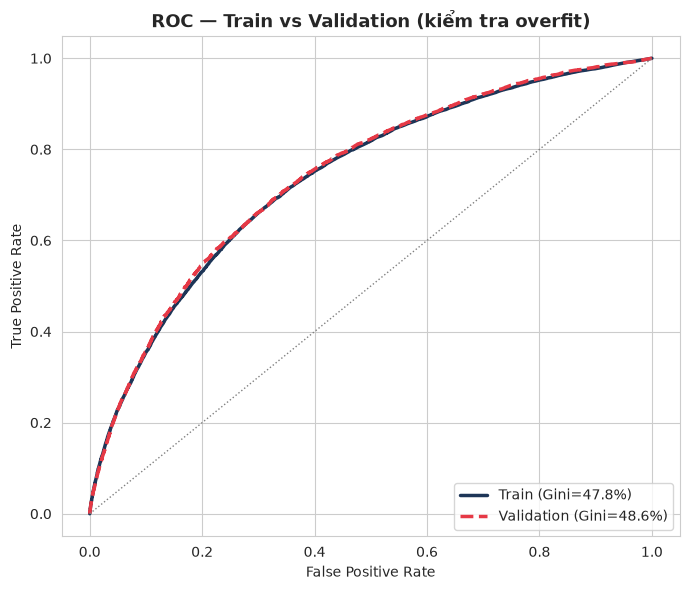


💾 Đã lưu: 5b.Model_Evaluation_Train_vs_Valid.png, 5b.gini_train_valid_summary.csv


,dataset,n_obs,bad_rate,AUC,Gini,KS,Gini_Gap_vs_Train
0,Train,208674,0.083,0.739,47.823,36.143,0.00
1,Validation,69558,0.083,0.743,48.613,36.434,-0.79


In [19]:
# 1. Áp luật WoE của Train sang Validation — dùng lại đúng hàm apply_woe_transformation
df_valid_raw = pd.read_csv(OUTPUT_DIR / "0.data_valid_split.csv")
df_valid_woe = apply_woe_transformation(df_valid_raw, df_rules, best_vars)
df_valid_woe = df_valid_woe.fillna(0)   # cùng lưới an toàn cho giá trị hiếm không khớp luật

y_valid = df_valid_woe[TARGET]
X_valid = df_valid_woe[best_vars]

# 2. Chấm bằng ĐÚNG mô hình đã fit trên Train — không fit lại
y_prob_valid = lr_model.predict_proba(X_valid)[:, 1]
auc_valid = roc_auc_score(y_valid, y_prob_valid)
gini_valid = (2 * auc_valid - 1) * 100
fpr_v, tpr_v, _ = roc_curve(y_valid, y_prob_valid)

df_ks_v = pd.DataFrame({'target': y_valid, 'prob': y_prob_valid}).sort_values('prob', ascending=False).reset_index(drop=True)
df_ks_v['cum_bads'] = df_ks_v['target'].cumsum() / df_ks_v['target'].sum()
df_ks_v['cum_goods'] = (1 - df_ks_v['target']).cumsum() / (1 - df_ks_v['target']).sum()
ks_valid = (df_ks_v['cum_bads'] - df_ks_v['cum_goods']).max() * 100

gap = gini - gini_valid
print(f"Gini Train      = {gini:.2f}%   | KS Train      = {ks_stat:.2f}%")
print(f"Gini Validation = {gini_valid:.2f}%   | KS Validation = {ks_valid:.2f}%")
print(f"Gap Gini (Train - Validation) = {gap:.2f} điểm %")
if gap < 5:
    print("-> ✅ Bình thường, mô hình tổng quát hóa tốt.")
elif gap < 10:
    print("-> ⚠️ Cảnh báo nhẹ, theo dõi thêm.")
else:
    print("-> ❌ Nghi overfit — xem lại MAX_FEATURES / leakage.")

# 3. Biểu đồ so sánh ROC Train vs Validation
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='#1D3557', lw=2.5, label=f'Train (Gini={gini:.1f}%)')
ax.plot(fpr_v, tpr_v, color='#E63946', lw=2.5, linestyle='--', label=f'Validation (Gini={gini_valid:.1f}%)')
ax.plot([0, 1], [0, 1], color='grey', lw=1, linestyle=':')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC — Train vs Validation (kiểm tra overfit)', fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
EVAL_VALID_CHART_PATH = OUTPUT_DIR / "5b.Model_Evaluation_Train_vs_Valid.png"
plt.savefig(EVAL_VALID_CHART_PATH, dpi=200, bbox_inches='tight')
plt.show()

# 4. Lưu bảng tóm tắt — Buổi 5 sẽ đọc file này để chấm tiêu chí overfit
summary_gini = pd.DataFrame([
    {'dataset': 'Train', 'n_obs': len(y), 'bad_rate': y.mean(), 'AUC': auc, 'Gini': gini, 'KS': ks_stat},
    {'dataset': 'Validation', 'n_obs': len(y_valid), 'bad_rate': y_valid.mean(), 'AUC': auc_valid, 'Gini': gini_valid, 'KS': ks_valid},
])
summary_gini['Gini_Gap_vs_Train'] = gini - summary_gini['Gini']
GINI_SUMMARY_PATH = OUTPUT_DIR / "5b.gini_train_valid_summary.csv"
summary_gini.to_csv(GINI_SUMMARY_PATH, index=False)
print(f"\n💾 Đã lưu: {EVAL_VALID_CHART_PATH.name}, {GINI_SUMMARY_PATH.name}")
summary_gini.round(3)